In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

from xgboost import XGBClassifier

In [3]:
RAW_DATA_PATH = Path("data/creditcard_1.csv")

MODEL_DIR = Path("models/xgboost_v1")
REPORT_DIR = Path("reports/v1_evaluation")

TARGET_COLUMN = "Class"
RANDOM_STATE = 42

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:

df = pd.read_csv(RAW_DATA_PATH)
df = df.sort_values("Time").reset_index(drop = True)

target_column = "Class"

split_index = int(len(df) * 0.8)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

X_train = train_df.drop(columns=[target_column])
y_train = train_df[target_column]

X_test = test_df.drop(columns=[target_column])
y_test = test_df[target_column]

In [5]:
v1_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    max_depth=3,
    learning_rate=0.2,
    n_estimators=300,
    scale_pos_weight=545.3908872901678,
    random_state=RANDOM_STATE,
)

v1_model.fit(
    X_train,
    y_train,
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.2, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None,
              num_parallel_tree=None, ...)

In [8]:
y_pred = v1_model.predict(X_test)
y_pred_proba = v1_model.predict_proba(X_test)[:, 1]

In [9]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

average_precision = average_precision_score(
    y_test,
    y_pred_proba,
)

roc_auc = roc_auc_score(
    y_test,
    y_pred_proba,
)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1: {f1:.4f}")
print(f"Average Precision: {average_precision:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

Precision: 0.8235
Recall: 0.7467
F1: 0.7832
Average Precision: 0.7968
ROC-AUC: 0.9883


[[56875    12]
 [   19    56]]


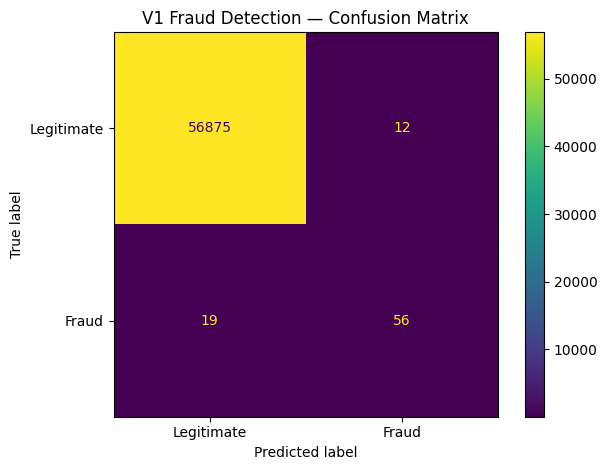

In [10]:
cm = confusion_matrix(
    y_test,
    y_pred,
)

print(cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"],
)

disp.plot()

plt.title("V1 Fraud Detection — Confusion Matrix")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

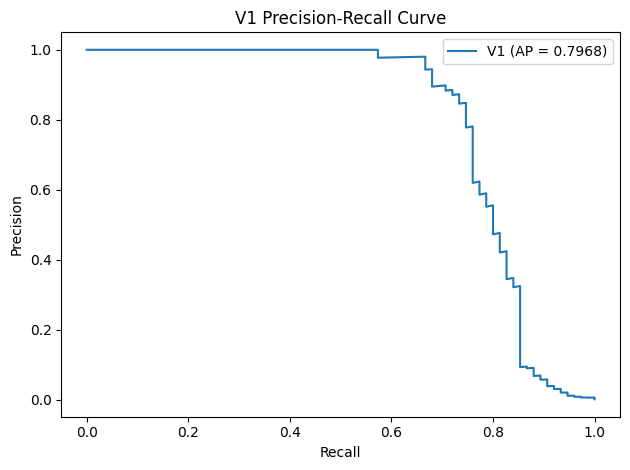

In [11]:
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_test,
        y_pred_proba,
    )
)
plt.figure()

plt.plot(
    recall_values,
    precision_values,
    label=f"V1 (AP = {average_precision:.4f})",
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("V1 Precision-Recall Curve")
plt.legend()

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [15]:
historical_results = pd.DataFrame(
    {
        "Model": [
            "Logistic Regression",
            "XGBoost + SMOTE",
            "XGBoost + scale_pos_weight (Pass 1)",
            "V1",
        ],
        "Precision": [
            0.9032,
            0.7532,
            0.8235,
            precision,
        ],
        "Recall": [
            0.3733,
            0.7733,
            0.7467,
            recall,
        ],
        "F1": [
            0.5283,
            0.7632,
            0.7832,
            f1,
        ],
        "Average Precision": [
            0.6726,
            0.7999,
            0.7968,
            average_precision,
        ],
    }
)

historical_results

,Model,Precision,Recall,F1,Average Precision
0,Logistic Regression,0.903200,0.373300,0.528300,0.672600
1,XGBoost + SMOTE,0.753200,0.773300,0.763200,0.799900
2,XGBoost + scale_pos_weight (Pass 1),0.823500,0.746700,0.783200,0.796800
3,V1,0.823529,0.746667,0.783217,0.796818


In [16]:
model_path = MODEL_DIR / "model.json"

v1_model.save_model(model_path)

print(f"Saved model to: {model_path}")

Saved model to: models\xgboost_v1\model.json


In [18]:
loaded_v1_model = XGBClassifier()

loaded_v1_model.load_model(model_path)
loaded_predictions = loaded_v1_model.predict_proba(
    X_test
)[:, 1]
loaded_ap = average_precision_score(
    y_test,
    loaded_predictions,
)

print(f"Reloaded model AP: {loaded_ap:.4f}")

Reloaded model AP: 0.7968
